# How does a song’s danceability relate to its popularity? 

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact

df = pd.read_csv("spotify_tracks_with_release.csv")

In [10]:
df[['track_name', 'artists', 'danceability', 'popularity']].head()

,track_name,artists,danceability,popularity
0,Comedy,Gen Hoshino,0.676,73
1,Ghost - Acoustic,Ben Woodward,0.420,55
2,To Begin Again,Ingrid Michaelson;ZAYN,0.438,57
3,Can't Help Falling In Love,Kina Grannis,0.266,71
4,Hold On,Chord Overstreet,0.618,82


In [11]:
df["danceability"].describe()

count    114000.000000
mean          0.566800
std           0.173542
min           0.000000
25%           0.456000
50%           0.580000
75%           0.695000
max           0.985000
Name: danceability, dtype: float64

### How is danceability distributed?

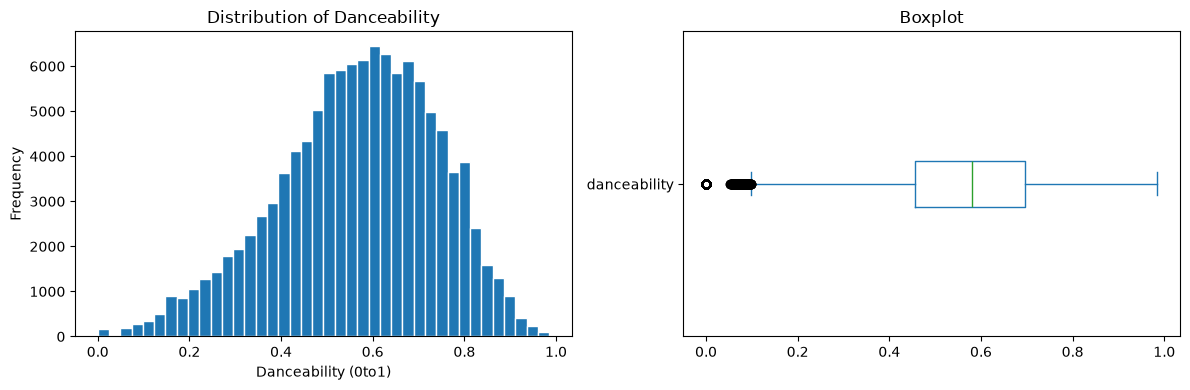

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["danceability"].plot(kind = 'hist', bins=40, ax=axes[0], edgecolor="white")
axes[0].set_title("Distribution of Danceability")
axes[0].set_xlabel("Danceability (0to1)")

df['danceability'].plot(kind="box", vert=False, ax=axes[1])
axes[1].set_title("Boxplot")
plt.tight_layout()
plt.show()

### Do popularity scores rise with danceability? 

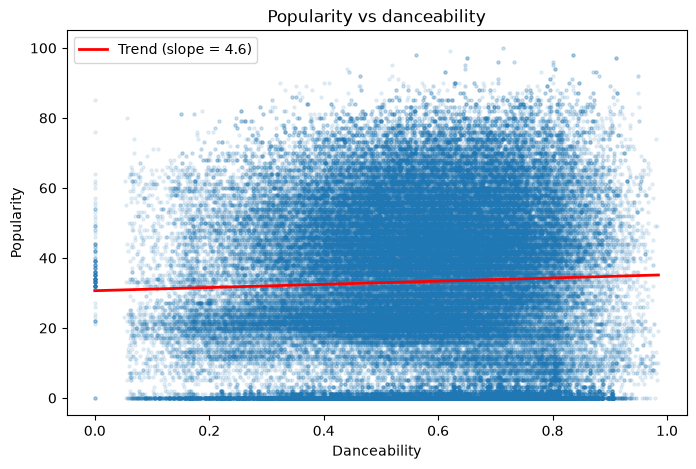

In [13]:
plt.figure(figsize=(8, 5))
plt.scatter(df["danceability"], df["popularity"], s=5, alpha=0.1)

m, b = np.polyfit(df["danceability"], df["popularity"], 1)
x = np.linspace(df["danceability"].min(), df["danceability"].max(), 100)
plt.plot(x, m * x + b, color="red", linewidth=2, label=f"Trend (slope = {m:.1f})")

plt.xlabel("Danceability")
plt.ylabel("Popularity")
plt.title("Popularity vs danceability")
plt.legend()
plt.show()


In [14]:
features = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
            'instrumentalness', 'liveness', 'valence', 'tempo']

@interact(
    feature=features,
    kind=['hexbin', 'scatter'],
    gridsize=(10, 60, 5),
    alpha=(.05, 1., .05)
)
def plot_vs_popularity(feature='danceability', kind='hexbin', gridsize=25,
                       alpha=.1, drop_zero_popularity=True, show_trend=True):
    data = df
    if drop_zero_popularity:
        data = data[data['popularity'] > 0]

    if kind == 'hexbin':
        ax = data.plot.hexbin(x=feature, y='popularity', gridsize=gridsize,
                              cmap='YlGnBu', figsize=(8, 5))
    else:
        ax = data.plot.scatter(x=feature, y='popularity', alpha=alpha,
                               s=5, figsize=(8, 5))

    if show_trend:
        m, b = np.polyfit(x=data[feature], y=data['popularity'], deg=1)
        xs = np.array([data[feature].min(), data[feature].max()])
        ax.plot(xs, m * xs + b, c='tab:orange', lw=2)

    r = data[feature].corr(data['popularity'])
    ax.set_title(f"Popularity vs {feature} (r = {r:.3f})")
    plt.show()

interactive(children=(Dropdown(description='feature', options=('danceability', 'energy', 'loudness', 'speechin…